# LSERBlm: обучение сербской LLM с нуля

- Данные → обработка → BPE → десять последовательных экспериментов.
- Для сравнения экспериментов используется пять тестовых семплов;
- Основная демонстрационная модель - последняя с SFT(**SFT 3e-5, best step=800**), для неё был проведен полный тест на 25 семплах

## Как устроены модели

Модель превращает токены в векторы, обрабатывает их последовательностью блоков и
вычисляет вероятности следующего токена. В каждом блоке attention связывает текущую
позицию с предыдущими, а FFN преобразует признаки каждой позиции.

- **Decoder-only, контекст 512.** Модель продолжает текст по одному токену. Vаксимум — 512 токенов контекста. Токен может быть словом, частью слова или знаком.
- **Позиции: absolute или RoPE.** В absolute к вектору токена добавляется обучаемый вектор его позиции. RoPE меняет векторы Q/K внутри attention в зависимости от позиции, позволяя учитывать взаимное расположение токенов. Мы сравниваем два способа задать порядок.
- **Pre-RMSNorm.** Перед attention и FFN масштаб входных векторов нормализуется.
  Это помогает контролировать величину активаций и поддерживать устойчивое обучение.
- **SwiGLU.** Внутри FFN одна обучаемая ветвь преобразует признаки, другая регулирует
  их вклад через поэлементное умножение. Это способ сделать преобразование признаков гибче.
- **GQA.** Несколько голов attention используют общие Key/Value-проекции.
  Например, у финальной модели 12 Query-голов и 4 набора Key/Value: один набор на три
  Query-головы. Так уменьшается число параметров K/V-проекций.
- **Связанные embeddings и LM head.** Одна матрица весов используется и для получения
  векторов токенов на входе, и для вычисления оценок токенов словаря на выходе.
  Это экономит параметры по сравнению с двумя отдельными матрицами.
- **QK-RMSNorm, отдельный эксперимент.** Q и K — векторы, по которым attention
  определяет связь между позициями. Их дополнительно нормализуют перед RoPE,
  чтобы контролировать масштаб значений при вычислении attention.
- **Повтор блоков с общими весами, тот же эксперимент.** Вместо A→B выполняется
  A→A→B→B: результат первого вызова блока подаётся в этот же блок ещё раз.
  Получается 28 уникальных блоков и 56 применений. Параметры повторно используются,
  вычислений становится больше. Этот вариант проверялся вместе с QK-RMSNorm.

## Как менялось обучение

- **Продолжение претрейна A/B.** Уже обученная Deep-модель продолжает учиться
  предсказывать следующий токен обычного текста. В A используются прежние 80,16M
  train-токенов, в B — расширенные 267,31M. Родитель и дополнительный бюджет одинаковые:
  так проверяется польза расширения данных. Архитектура не меняется.
- **SFT.** Та же собственная модель обучается на сербских инструкциях с готовыми ответами.
  Вопрос служит контекстом, а ошибка считается только по токенам ответа и EOS — признаку
  его окончания. Обновляются все веса. Сравниваются LR 1e-5 и 3e-5: learning rate задаёт
  масштаб изменения весов на шаге. Цель — научить модель отвечать в нужном формате.


In [ ]:
from pathlib import Path
import sys
from datetime import datetime
from zoneinfo import ZoneInfo

import torch
from IPython.display import Markdown, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from serbian_llm.experiments import RUN_NAMES, read_metrics, run_summary
from serbian_llm.inference import Generator
from serbian_llm.utils import read_json, read_jsonl

DEVICE = "cpu"
PRECISION = "fp32"
torch.set_num_threads(4)
print(datetime.now(ZoneInfo("Europe/Moscow")).strftime("%d.%m.%Y %H:%M МСК"))
print("Устройство:", DEVICE, "точность:", PRECISION)


25.10.2026 22:11 МСК
Устройство: cpu точность: fp32


## Данные

Сербская кириллица: Wikipedia `20231101.sr` и FineWeb2 `srp_Cyrl`.
Исходный корпус содержит 499,5 МБ очищенного текста всех разбиений и 80,16M
train-токенов. Расширенный train — 267,31M токенов. Validation/test при расширении
сохранены побайтово; test не используется для выбора модели.

Для SFT: сербская часть EuroAlpaca, CC BY-NC 4.0; после фильтров **18 580 train /
1 047 validation / 1 028 test**, 2,82M входных и 2,24M обучаемых токенов train.
Данные синтетические, ошибки перевода и фактов возможны.


In [ ]:
corpora = {
    "Исходный": ROOT / "data/serbian_mix_v2",
    "Расширенный": ROOT / "data/serbian_expanded_v3",
}
lines = ["| Корпус | Train-документы | Train-токены | UTF-8 train, МБ | Токенов/слово |",
         "|---|---:|---:|---:|---:|"]
for label, folder in corpora.items():
    manifest = read_json(folder / "corpus/manifest.json")
    stats = read_json(folder / "bpe8k/token_stats.json")["splits"]["train"]
    lines.append(f"| {label} | {stats['documents']:,} | {stats['tokens']:,} | "f"{stats['text_bytes']/1e6:.1f} | {stats['tokens_per_word']:.3f} |")
display(Markdown("\n".join(lines)))


| Корпус | Train-документы | Train-токены | UTF-8 train, МБ | Токенов/слово |
|---|---:|---:|---:|---:|
| Исходный | 78,484 | 80,159,914 | 489.9 | 1.963 |
| Расширенный | 250,886 | 267,310,738 | 1669.2 | 1.909 |

## Обработка

- NFC, длина текста и число слов; язык по метаданным и сербская письменность.
- Отбраковка повторов, списков и страниц неоднозначностей Wikipedia.
- Exact/MinHash-дедупликация; при расширении — удаление служебных хвостов, меню/таблиц.
- Проверка нового train против исходных и очищенных holdout; validation/test не меняются.
- Фильтрация новой стадии не отменяет прежнего пересечения у родителя.
- Код: `streaming.py`, `preparation.py`, `data.py`, `expansion.py`.

- SFT: проверка кириллицы и метаданных постредакции, удаление дублей/длинных ответов,
  исключение математики и кода; одинаковые контексты сгруппированы между split.
- Подготовка SFT: `scripts/prepare_sft_sr_1.py`; отчёт — `benchmarks/sft_data_report.json`.


In [3]:
audit = read_json(ROOT / "data/serbian_expanded_v3/corpus/split_audit.json")
print({key: value for key, value in audit.items() if key != "shared_paragraph_examples"})

seen_sources = set()
for row in read_jsonl(ROOT / "data/serbian_expanded_v3/corpus/train.jsonl"):
    source = row.get("source", "local")
    if source not in seen_sources:
        print("\nИСТОЧНИК:", source)
        print(row["text"][:800])
        seen_sources.add(source)
    if len(seen_sources) == 2:
        break


{'exact_cross_split_documents': 0, 'shared_long_paragraph_occurrences': 8, 'minimum_paragraph_characters': 200, 'shared_paragraph_split_pairs': {'validation:test': 8}, 'note': 'Shared paragraphs can be quotations or boilerplate; inspect before interpreting as leakage.'}

ИСТОЧНИК: wikimedia/wikipedia
Мирослав (; умро 949) је био краљ Хрватске од 945. до 949. године.

Биографија 
Мирослав је припадао династији Трпимировића. Био је старији син хрватског краља Крешимира I (935—945) и брат Михаила Крешимира II. На власт је дошао након очеве смрти. Летопис попа Дукљанина бележи грађански рат који је вођен у Хрватској током Мирослављеве владавине. Рат је покренуо краљев брат Михаило. Мирослав је изгубио већину земаља у Босни. Њих заузима српски кнез Часлав Клонимировић. Византинци су настојали да поврате своје поседе у Далмацији. Хрватска флота је у то време имала око 30 бродова. Мирослав је 949. године убијен од стране кнеза Прибине. Михаило га је наследио на хрватском престолу.

Породично 


ИСТОЧНИК: HuggingFaceFW/fineweb-2
Према програму посете шефа руске државе, Путину ће на Аеродрому „Никола Тесла“ бити приређен дочек, након којег ће бити одржана церемонија полагања венаца на Гробљу ослободилаца Београда и Црвеноармејцу.
Церемонија свечаног дочека руског председнка испред Палате Србија предвиђена је за 12.45 сати, након чега ће уследити састанак у ужем формату двојице председника, Вучића и Путина.
Сат након тога планиран је састанак делегација Србије и Русије, а потом и потписивање билатералних докумената у присуству двојице председника.
За по подне је предвиђена церемонија уручења Ордена Александра Невског председнику Србије Александру Вучићу.
Орден Вучићу ће уручити председник Путин. Двојица председника ће се након тога обратити медијима. А по давању изјава планиран је обилазак Храма Светог Саве.
Завршне


## Токенизатор

- **ByteLevel BPE, 8192 токена**, обучен только на исходном train.
- **NFC:** сохраняются регистр, сербские окончания и диакритика.
- **PAD/BOS/EOS/UNK**, документ: `BOS + text + EOS`; хранение `.bin` в uint16.
- **Один словарь для всех моделей:** новый корпус закодирован прежним BPE.
- **Новый train:** 1,91 токена на слово, UNK=0; последнее само по себе не доказывает качество сегментации.
- Код: `tokenization.py`.

- В SFT используется тот же BPE; формат `Питање: …\nОдговор: …`.
  Prompt и padding маскируются в loss, ответ и EOS обучаются; ответы не обрезаются.

На исходном train 0,660% лексических токенов словаря не используются, 0,672%
встречаются реже пяти раз (`token_stats.json`, `token_frequencies.jsonl`).
Сравнение размеров словаря и BPE/Unigram не проводилось.


In [4]:
from tokenizers import Tokenizer

tokenizer_folder = ROOT / "data/serbian_mix_v2/bpe8k"
tokenizer = Tokenizer.from_file(str(tokenizer_folder / "tokenizer.json"))
meta = read_json(tokenizer_folder / "tokenizer_meta.json")
print("Размер словаря:", tokenizer.get_vocab_size())
print("Специальные токены:", meta["special_ids"])
text = "Милица је јуче отишла у библиотеку. Тамо је читала књигу."
encoded = tokenizer.encode(text)
print("Исходный текст:", text)
print("ID:", encoded.ids)
print("Обратное преобразование:", tokenizer.decode(encoded.ids))


Размер словаря: 8192
Специальные токены: {'[PAD]': 0, '[BOS]': 1, '[EOS]': 2, '[UNK]': 3}
Исходный текст: Милица је јуче отишла у библиотеку. Тамо је читала књигу.
ID: [4846, 538, 299, 7854, 4303, 729, 289, 3250, 1803, 17, 444, 822, 299, 2011, 542, 7153, 17]
Обратное преобразование: Милица је јуче отишла у библиотеку. Тамо је читала књигу.


## Обучение и размеры моделей

- AdamW, BF16, SDPA, WSD, gradient clipping=1.
- Effective batch=32, 16 384 токена на обновление.
- Первые пять моделей: 20 000 шагов, 327,68M предъявлений токенов.
- A/B: родитель Deep №2; одинаковые дополнительные 30 518 шагов / 500,01M токенов.
- Таблица читает реальные checkpoint. Время — чистые train-шаги, без eval/генераций/IO.
- Код: `model.py`, `training.py`, `batching.py`, `checkpoints.py`.

- SFT: AdamW заново, cosine, warmup 70, microbatch 8×accumulation 4, BF16/SDPA.
- До 2 323 шагов, примерно четыре объёма train при выборке с возвращением.
  Полная SFT-validation каждые 100 шагов, patience=5, min_delta=0,001.


In [5]:
lines = ["| Запуск | Параметры | Шаг / план | Чистое время, ч | Шаг времени | Best step | Статус |",
         "|---|---:|---:|---:|---:|---:|---|"]
for name in RUN_NAMES:
    s = run_summary(ROOT / "runs" / name)
    status = "завершён" if s["complete"] else "не завершён"
    lines.append(f"| {name} | {s['parameters']:,} | {s['step']:,} / {s['max_steps']:,} | "
                 f"{s['training_seconds']/3600:.2f} | {s['timing_checkpoint_step']:,} | "
                 f"{s['best_step']:,} | {status} |")
display(Markdown("\n".join(lines)))


| Запуск | Параметры | Шаг / план | Чистое время, ч | Шаг времени | Best step | Статус |
|---|---:|---:|---:|---:|---:|---|
| absolute_41m | 41,109,888 | 20,000 / 20,000 | 2.19 | 20,000 | 20,000 | завершён |
| rope_41m | 40,913,280 | 20,000 / 20,000 | 2.74 | 20,000 | 20,000 | завершён |
| serbian_283m_1 | 283,170,240 | 20,000 / 20,000 | 1.84 | 20,000 | 20,000 | завершён |
| serbian_283m_2 | 283,183,872 | 20,000 / 20,000 | 2.16 | 20,000 | 20,000 | завершён |
| serbian_283m_3 | 283,173,824 | 20,000 / 20,000 | 4.75 | 20,000 | 20,000 | завершён |
| deep_continue_A | 283,183,872 | 30,518 / 30,518 | 3.30 | 30,518 | 500 | завершён |
| deep_continue_B | 283,183,872 | 30,518 / 30,518 | 3.30 | 30,518 | 30,518 | завершён |

## Сопоставимая validation

У первых пяти моделей одинаковые 32 packed-окна; у A/B — одинаковые 64 окна.
Поэтому графики разных стадий разделены. Это не документная perplexity:
полная validation сбрасывает контекст на документе и оценивает каждый content-токен
ровно один раз, stride=256, EOS исключён.

Полная document-level validation ниже: все 828 документов, stride=256, BF16 на GPU;
сводка сохранена в `benchmarks/model_comparison.json`. Генерации далее выполняются на CPU / FP32.


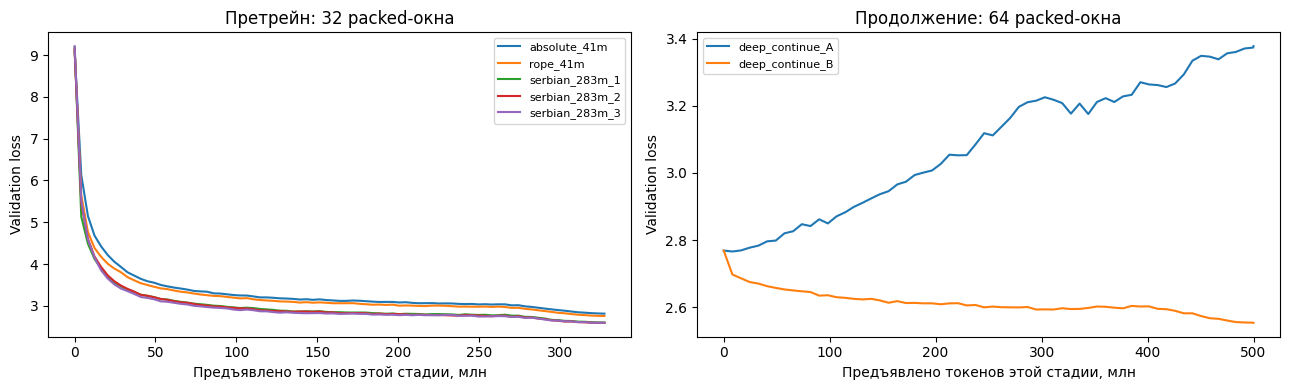

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, names, title in [(axes[0], RUN_NAMES[:5], "Претрейн: 32 packed-окна"),
                         (axes[1], RUN_NAMES[5:], "Продолжение: 64 packed-окна")]:
    for name in names:
        rows = [r for r in read_metrics(ROOT / "runs" / name / "metrics.jsonl") if "validation_loss" in r]
        ax.plot([r["processed_input_tokens"] / 1e6 for r in rows],
                [r["validation_loss"] for r in rows], label=name)
    ax.set(title=title, xlabel="Предъявлено токенов этой стадии, млн", ylabel="Validation loss")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


In [7]:
comparison = read_json(ROOT / "benchmarks/model_comparison.json")
lines = ["| Модель | Best step | Полная validation PPL | Bits/byte |", "|---|---:|---:|---:|"]
for name, values in comparison["runs"].items():
    lines.append(f"| {name} | {values['checkpoint_step']} | {values['perplexity']:.3f} | {values['bits_per_byte']:.5f} |")
display(Markdown("\n".join(lines)))
best_run = min(comparison["runs"], key=lambda name: comparison["runs"][name]["nll_per_token"])
print("Лучшая по полной validation:", best_run)


| Модель | Best step | Полная validation PPL | Bits/byte |
|---|---:|---:|---:|
| absolute_41m | 20000 | 19.618 | 0.70514 |
| rope_41m | 20000 | 18.613 | 0.69268 |
| serbian_283m_1 | 20000 | 16.608 | 0.66569 |
| serbian_283m_2 | 20000 | 16.521 | 0.66445 |
| serbian_283m_3 | 20000 | 16.664 | 0.66647 |
| deep_continue_A | 500 | 16.602 | 0.66560 |
| deep_continue_B | 30518 | 13.588 | 0.61813 |

Лучшая по полной validation: deep_continue_B


### Метрики SFT

| Модель | Best step | Завершено шагов | Чистое обучение | SFT-val NLL ↓ | SFT-test NLL ↓ | LM-val PPL ↓ |
|---|---:|---:|---|---:|---:|---:|
| B до SFT | 30 518 | — | — | 2,638 | 2,640 | **13,588** |
| SFT 1e-5 | 2 323 | 2 323 | 21 мин 28 с | 2,291 | 2,278 | 14,450 |
| SFT 3e-5 | **800** | 1 300, early stop | 12 мин 04 с | **2,284** | **2,270** | 15,293 |

Checkpoint для SFT выбран по полной SFT-validation, до разбора генераций.
NLL ответа/EOS и обычная LM PPL измеряют разные свойства; SFT улучшил первое,
но ухудшил второе. Время — train-шаги без eval/IO; A100 80GB. Отчёт —
`benchmarks/sft_comparison.json`.


## Эксперименты

- Ниже сначала показаны пять общих вводов: CPU / FP32, максимум 32 новых токена,
  temperature=0.8, top_k=40, seed=42. Общая функция `infer` только вызывает генерацию.
- Для финальной SFT используется облегчённый `benchmarks/serbian_25_v2.jsonl`:
  те же пять вводов и ещё 20 простых заданий на продолжение, контекст и короткий рассказ.
  В этих 20 примерах лимит увеличен до 64 токенов, чтобы было место для нескольких предложений.
- Вопросы финальной SFT — greedy в формате `Питање/Одговор`, продолжения — исходный текст.
- Ответы не отбираются по удачности. Переводы и комментарии добавлены вручную.
  Новый набор отличается от прежнего; его результаты не считаются улучшением на старом бенчмарке.

- Примеры составлены отдельно. Проверка всех полных вводов после NFC, приведения
  регистра и пробелов не нашла совпадений в SFT-train или исходном pretrain-train.
  В расширенном pretrain-train встречаются №21 «Србија је држава која се налази у»
  (1 документ) и №22 «Београд је главни град» (5 документов). Поэтому это демонстрационный
  набор, а не полностью невиданный test; смысловые парафразы отдельно не проверялись.
  Отчёт — `benchmarks/serbian_25_v2_train_overlap.json`.


In [8]:
benchmark = list(read_jsonl(ROOT / "benchmarks/serbian_25_v2.jsonl"))
examples = benchmark[:5]
for example in examples:
    print(f"№{example['id']}: {example['prompt']}")


def infer(model, prompt, temperature=0.8, max_new_tokens=32):
    return model.generate(
        prompt, max_new_tokens=max_new_tokens, temperature=temperature, top_k=40, seed=42
    )["completion"]


№21: Србија је држава која се налази у
№22: Београд је главни град
№23: Пас је домаћа животиња. Он
№24: Ујутру сам устао и
№25: Данас је леп дан. Деца се играју у


### 1. Absolute 41M

- **Размер:** 41,11M; 24×384, FFN 1024, Q/KV 6/2, контекст 512.
- **Метод:** обучаемые absolute positions; RMSNorm, SwiGLU, GQA, связанные embeddings.
- **Зачем:** контроль для сравнения позиционной схемы с RoPE.
- **Обучение:** исходный train 80M, 20 000 шагов, 2 ч 12 мин чистого времени.


In [9]:
model = Generator(ROOT / "runs/absolute_41m/best.pt", device="cpu", precision="fp32")
print("Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


Best step: 20000

№21 | Србија је држава која се налази у


 саставу Србије са највећим делом своје територије.

На територији Србије, поред Србије, налази се и град Србија, који је у саставу Србије са око 3

№22 | Београд је главни град


 у Србији са највећим бројем посетилаца и више од 1.200 посетилаца. Са само 15.000 посетилаца посетилаца у Београду, са око 3

№23 | Пас је домаћа животиња. Он


 је ловац на крзнени лав у кући, живи у кући, има само паразити, може да спава, живи са животом

№24 | Ујутру сам устао и


 у јулу, а онда је почео да ме ухвати, пао сам у полицију. Кажу да је моја мајка унук са којом сам

№25 | Данас је леп дан. Деца се играју у


 градовима са богатом храном, богатом храном, пићу, воћним и другим стварима.
Гости из Тешња долазе


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | саставу Србије са највећим делом своје територије.<br><br>На територији Србије, поред Србије, налази се и град Србија, који је у саставу Србије са око 3 | составе Сербии с большей частью своей территории. На территории Сербии, кроме Сербии, находится и город Сербия, входящий в состав Сербии с примерно 3 |
| 22 | Београд је главни град | у Србији са највећим бројем посетилаца и више од 1.200 посетилаца. Са само 15.000 посетилаца посетилаца у Београду, са око 3 | в Сербии с наибольшим числом посетителей и более чем 1 200 посетителями. Всего с 15 000 посетителей посетителей в Белграде, с примерно 3 |
| 23 | Пас је домаћа животиња. Он | је ловац на крзнени лав у кући, живи у кући, има само паразити, може да спава, живи са животом | охотник на меховой лев в доме, живёт в доме, имеет только паразиты, может спать, живёт с жизнью [ошибки оригинала сохранены] |
| 24 | Ујутру сам устао и | у јулу, а онда је почео да ме ухвати, пао сам у полицију. Кажу да је моја мајка унук са којом сам | в июле, а затем он начал меня ловить, я упал в полицию. Говорят, что моя мать — внук, с которой я |
| 25 | Данас је леп дан. Деца се играју у | градовима са богатом храном, богатом храном, пићу, воћним и другим стварима.<br>Гости из Тешња долазе | городах с богатой едой, богатой едой, питьём, фруктовыми и другими вещами. Гости из Тешня приезжают |

**Комментарий.** В отдельных фразах сохраняется сербская грамматика, но ответы быстро переходят к повторам и смысловым сбоям.


### 2. RoPE 41M

- **Размер:** 40,91M; 24×384, FFN 1024, Q/KV 6/2.
- **Добавлено:** RoPE вместо обучаемых абсолютных позиций.
- **Зачем:** проверить позиционное кодирование без отдельной таблицы embeddings.
- **Обучение:** исходный train 80M, 20 000 шагов, 2 ч 45 мин.


In [10]:
model = Generator(ROOT / "runs/rope_41m/best.pt", device="cpu", precision="fp32")
print("Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


Best step: 20000

№21 | Србија је држава која се налази у


 фиоку међународног права. Ако је држава у питању, она треба да се промени. Кремљ постаје држава у којој сви Срби са којима жив

№22 | Београд је главни град


 у Србији са преко 1.500 становника.

На овом месту, поред Београда, налази се и град Београд.

Демографија 
Према

№23 | Пас је домаћа животиња. Он


 је врста са ротацијом око главе и леђа у облику крила, која се налази само на рукама. Одликује се широким, са широким

№24 | Ујутру сам устао и


 у воду са пиштољем почео да нећу да скидам своју торбу коју сам одувек желео, а то је био њихов живот.

№25 | Данас је леп дан. Деца се играју у


 флашама, а деца играју у флашама.
Завршавају се у парку. Како смо ми, а шта људи, са њима ћемо


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | фиоку међународног права. Ако је држава у питању, она треба да се промени. Кремљ постаје држава у којој сви Срби са којима жив | ящике международного права. Если речь о государстве, оно должно измениться. Кремль становится государством, в котором все сербы, с которыми жив [обрыв] |
| 22 | Београд је главни град | у Србији са преко 1.500 становника.<br><br>На овом месту, поред Београда, налази се и град Београд.<br><br>Демографија <br>Према | в Сербии с более чем 1 500 жителями. На этом месте, кроме Белграда, находится и город Белград. Демография. Согласно |
| 23 | Пас је домаћа животиња. Он | је врста са ротацијом око главе и леђа у облику крила, која се налази само на рукама. Одликује се широким, са широким | вид с вращением вокруг головы и спины в форме крыла, которая находится только на руках. Отличается широким, с широким |
| 24 | Ујутру сам устао и | у воду са пиштољем почео да нећу да скидам своју торбу коју сам одувек желео, а то је био њихов живот. | в воду с пистолетом начал, что не буду снимать свою сумку, которую всегда хотел, а это была их жизнь [сбивчивая конструкция оригинала] |
| 25 | Данас је леп дан. Деца се играју у | флашама, а деца играју у флашама.<br>Завршавају се у парку. Како смо ми, а шта људи, са њима ћемо | бутылках, а дети играют в бутылках. Они заканчиваются в парке. Как мы, а что люди, с ними мы будем |

**Комментарий.** В №22 правильно названа Сербия; затем появляются повторы и фрагменты списка. Остальные продолжения сбивчивы.


### 3. Wide 283M

- **Размер:** 283,17M; 28×960, FFN 2560, Q/KV 15/5.
- **Добавлено:** больше ширины, FFN и голов по сравнению с 41M.
- **Зачем:** проверить пользу увеличения ёмкости модели.
- **Обучение:** исходный train 80M, 20 000 шагов, 1 ч 50 мин.


In [11]:
model = Generator(ROOT / "runs/serbian_283m_1/best.pt", device="cpu", precision="fp32")
print("Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


Best step: 20000

№21 | Србија је држава која се налази у


 западној Европи, која је заузимала територије у којима су се развијале трговачке и војне снаге.
У том смислу, како је истакнуто

№22 | Београд је главни град


 Републике Србије.

Историја 
Булевар

Оснивање трговишта 
Почетком 17. века у Београду је избио сукоб

№23 | Пас је домаћа животиња. Он


 преферира домаће зечеве, у којима се налази пецарош и не дозвољавају женкама да спавају, како са подручја Дал

№24 | Ујутру сам устао и


 пољубио главу,
не могући ни у миру, ни у миру.
Није то што ви овде у Тарама,


№25 | Данас је леп дан. Деца се играју у


 фиоку, а по потреби и лампиони.
Деца се играју у фиоку
У фиоку можете да се игр


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | западној Европи, која је заузимала територије у којима су се развијале трговачке и војне снаге.<br>У том смислу, како је истакнуто | Западной Европе, которая занимала территории, где развивались торговые и военные силы. В этом смысле, как было отмечено |
| 22 | Београд је главни град | Републике Србије.<br><br>Историја <br>Булевар<br><br>Оснивање трговишта <br>Почетком 17. века у Београду је избио сукоб | Республики Сербии. История. Бульвар. Основание торгового поселения. В начале XVII века в Белграде вспыхнул конфликт |
| 23 | Пас је домаћа животиња. Он | преферира домаће зечеве, у којима се налази пецарош и не дозвољавају женкама да спавају, како са подручја Дал | предпочитает домашних кроликов, в которых находится рыболов, и не позволяют самкам спать, как с территории Дал [обрыв] |
| 24 | Ујутру сам устао и | пољубио главу,<br>не могући ни у миру, ни у миру.<br>Није то што ви овде у Тарама, | поцеловал голову, не в силах ни в покое, ни в покое. Это не то, что вы здесь в Тарах, |
| 25 | Данас је леп дан. Деца се играју у | фиоку, а по потреби и лампиони.<br>Деца се играју у фиоку<br>У фиоку можете да се игр | ящике, а при необходимости и фонарики. Дети играют в ящике. В ящике вы можете игр [обрыв] |

**Комментарий.** Начало о Белграде уместно, затем появляются заголовки и посторонняя история. В географии и бытовых сценах остаются ошибки.


### 4. Deep 283M

- **Размер:** 283,18M; 44×768, FFN 2048, Q/KV 12/4.
- **Добавлено:** больше слоёв при меньшей ширине и почти том же числе параметров, что у Wide.
- **Зачем:** сравнить глубину и ширину; лучший LM-validation loss среди трёх архитектур 283M.
- **Обучение:** исходный train 80M, 20 000 шагов, 2 ч 10 мин; родитель веток A/B.


In [12]:
model = Generator(ROOT / "runs/serbian_283m_2/best.pt", device="cpu", precision="fp32")
print("Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


Best step: 20000

№21 | Србија је држава која се налази у


 просперитету и стабилности, која је у стабилности и кризи. Са другим странама света је она која је у кризи са којом се

№22 | Београд је главни град


 Републике Србије са богатим културним и туристичком делатношћу. У складу са својим могућностима, град је познат и као "Београдски круг 2",

№23 | Пас је домаћа животиња. Он


 је сферични, дугачак и разгранат. Има дугачак врат и жилаво кљун. Тешко га је

№24 | Ујутру сам устао и


 погледао шта ми је рекао Исус Христос у својој књизи “Ти си Бог Израиљевог обличја” (Друга Тројица),

№25 | Данас је леп дан. Деца се играју у


 празничном бадему, док одрасли у маштовитом друштву ведрог духа, лепог понашања, ритуалима и


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | просперитету и стабилности, која је у стабилности и кризи. Са другим странама света је она која је у кризи са којом се | процветании и стабильности, которая в стабильности и кризисе. С другими частями света она та, которая в кризисе, с которой [обрыв фразы] |
| 22 | Београд је главни град | Републике Србије са богатим културним и туристичком делатношћу. У складу са својим могућностима, град је познат и као &quot;Београдски круг 2&quot;, | Республики Сербии с богатым культурным и туристической деятельностью [сбой согласования]. В соответствии со своими возможностями город также известен как «Белградский круг 2», |
| 23 | Пас је домаћа животиња. Он | је сферични, дугачак и разгранат. Има дугачак врат и жилаво кљун. Тешко га је | сферический, длинный и разветвлённый. У него длинная шея и жилистое клюв [сбой согласования]. Трудно его |
| 24 | Ујутру сам устао и | погледао шта ми је рекао Исус Христос у својој књизи “Ти си Бог Израиљевог обличја” (Друга Тројица), | посмотрел, что сказал мне Иисус Христос в своей книге «Ты Бог облика Израилева» (Другая Троица), |
| 25 | Данас је леп дан. Деца се играју у | празничном бадему, док одрасли у маштовитом друштву ведрог духа, лепог понашања, ритуалима и | праздничном миндале, тогда как взрослые — в творческом обществе бодрого духа, хорошего поведения, ритуалах и |

**Комментарий.** Описание Белграда дольше держится на одной теме, но другие ответы содержат странные характеристики и смену ситуации.


### 5. QK-RMSNorm + block sharing

- **Размер:** 283,17M; 28×960, FFN 2560, Q/KV 15/5.
- **Добавлено:** QK-RMSNorm перед RoPE и повтор каждого блока A→A→B→B с общими весами.
- **Зачем:** проверить контроль масштаба attention и дополнительную вычислительную глубину.
- **Обучение:** 28 уникальных блоков / 56 применений, 20 000 шагов, 4 ч 45 мин.
  Две особенности проверялись вместе; отдельный эффект каждой не измерен.


In [13]:
model = Generator(ROOT / "runs/serbian_283m_3/best.pt", device="cpu", precision="fp32")
print("Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


Best step: 20000

№21 | Србија је држава која се налази у


 западној хемисфери, са изузетком у Швајцарској, која је четврти пут у историји увела обавезно ношење оружја, за

№22 | Београд је главни град


 земље са најконкурентнијом економијом у Европи, што значи да се не може градити нове, мање развијене земље са негативним

№23 | Пас је домаћа животиња. Он


 је јака, моћна и интелигентна животиња, способна да обавља разне задатке. Овај пас може бити било ко, чак и ако није

№24 | Ујутру сам устао и


 рекао – шта могу да учиним да ме не ухвате?
Чудно је да се осећам као да ме жена прогања са мог ч

№25 | Данас је леп дан. Деца се играју у


 фитнес клубу „Принцеза“ у Београду, где је у пратњи ђака од 5—6 година у једној посети школи са наставн


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | западној хемисфери, са изузетком у Швајцарској, која је четврти пут у историји увела обавезно ношење оружја, за | Западном полушарии, с исключением в Швейцарии, которая в четвёртый раз в истории ввела обязательное ношение оружия, для |
| 22 | Београд је главни град | земље са најконкурентнијом економијом у Европи, што значи да се не може градити нове, мање развијене земље са негативним | страны с самой конкурентоспособной экономикой в Европе, что означает, что нельзя строить новые, менее развитые страны с отрицательным |
| 23 | Пас је домаћа животиња. Он | је јака, моћна и интелигентна животиња, способна да обавља разне задатке. Овај пас може бити било ко, чак и ако није | сильное, могучее и умное животное, способное выполнять разные задачи. Этот пёс может быть кем угодно, даже если он не |
| 24 | Ујутру сам устао и | рекао – шта могу да учиним да ме не ухвате?<br>Чудно је да се осећам као да ме жена прогања са мог ч | сказал: что я могу сделать, чтобы меня не поймали? Странно, что я чувствую, будто жена преследует меня с моего ч [обрыв] |
| 25 | Данас је леп дан. Деца се играју у | фитнес клубу „Принцеза“ у Београду, где је у пратњи ђака од 5—6 година у једној посети школи са наставн | фитнес-клубе «Принцесса» в Белграде, где в сопровождении учеников 5–6 лет во время одного посещения школы с учит [обрыв; фраза сбивчива] |

**Комментарий.** Описание собаки начинается связно; в ответах про утро и детей частично удерживается тема. Фактические ошибки и уход от исходного ввода сохраняются.


### 6. Продолжение A: прежний корпус

- **Размер:** 283,18M; архитектура Deep без изменений.
- **Добавлено:** continued pretraining от Deep, новый AdamW/WSD на прежних 80M токенов.
- **Зачем:** контроль эффекта дополнительного обучения без расширения данных.
- **Обучение:** ещё 30 518 шагов / 500,01M предъявлений токенов, 3 ч 18 мин;
  ниже best на шаге 500.


In [14]:
model = Generator(ROOT / "runs/deep_continue_A/best.pt", device="cpu", precision="fp32")
print("Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


Best step: 500

№21 | Србија је држава која се налази у


 просперитету и стабилности, која је у миру и стабилности, упркос свим тешкоћама и изазовима.
„Српска ствар

№22 | Београд је главни град


 франкофоније и један је од најстаријих градова у Европи. По подацима из 1887. године, у граду је живело 7.930 становника

№23 | Пас је домаћа животиња. Он


 је сферни члан породице зечева ().

Опис 

Настањивање је могуће у другој половини октобра, са северних

№24 | Ујутру сам устао и


 пренео лоповицу на мене.
Отишао сам у ресторан и био сам у кондицији, а у ресторану сам остао

№25 | Данас је леп дан. Деца се играју у


 празничном бадему, а одрасли у колицима. Слике из дечијих филмова и цртаних филма су увек занимљиве са дечијим


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | просперитету и стабилности, која је у миру и стабилности, упркос свим тешкоћама и изазовима.<br>„Српска ствар | процветании и стабильности, которая в мире и стабильности, несмотря на все трудности и вызовы. «Сербское дело |
| 22 | Београд је главни град | франкофоније и један је од најстаријих градова у Европи. По подацима из 1887. године, у граду је живело 7.930 становника | франкофонии и один из старейших городов Европы. По данным 1887 года, в городе проживало 7 930 жителей |
| 23 | Пас је домаћа животиња. Он | је сферни члан породице зечева ().<br><br>Опис <br><br>Настањивање је могуће у другој половини октобра, са северних | сферический член семейства кроликов (). Описание. Заселение возможно во второй половине октября, с северных |
| 24 | Ујутру сам устао и | пренео лоповицу на мене.<br>Отишао сам у ресторан и био сам у кондицији, а у ресторану сам остао | перенёс воровку на меня. Я пошёл в ресторан и был в хорошей форме, а в ресторане я остался |
| 25 | Данас је леп дан. Деца се играју у | празничном бадему, а одрасли у колицима. Слике из дечијих филмова и цртаних филма су увек занимљиве са дечијим | праздничном миндале, а взрослые — в колясках. Кадры из детских фильмов и мультфильмов всегда интересны с детским |

**Комментарий.** Дополнительный претрейн на прежних данных не дал заметного улучшения этой пятёрки: остаются неверные факты и нелогичные продолжения.


### 7. Продолжение B: расширенный корпус

- **Размер:** 283,18M; Deep и BPE-8192 без изменений.
- **Добавлено:** очищенный расширенный train 267,31M вместо 80,16M токенов.
- **Зачем:** сравнить с A при одинаковом родителе, бюджете и расписании обучения.
- **Обучение:** ещё 30 518 шагов / 500,01M предъявлений токенов, 3 ч 18 мин;
  best — финальный шаг. LM-validation PPL 13,588.


In [15]:
model = Generator(ROOT / "runs/deep_continue_B/best.pt", device="cpu", precision="fp32")
print("Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


Best step: 30518

№21 | Србија је држава која се налази у


 западној Европи, а по броју становника је четврта на Балкану. По подацима из 2021. године, Србија је на другом месту на светској ранг-

№22 | Београд је главни град


 Републике Србије са богатим културним наслеђем и преко 15.000 градова и општина налази се у главном граду.
Држава Србија са поносом

№23 | Пас је домаћа животиња. Он


 је увек био добар друг и зујати у њега.
Не треба заборавити да се пас често користи као пратилац.
Власника често сматрају

№24 | Ујутру сам устао и


 прочишћен, по твом милом лицу мило.
Чудо моје, Господе, молим те опрости, да ми опр

№25 | Данас је леп дан. Деца се играју у


 флашама, а деца играју у флашама.
Здраво! Дете не може да се хода. Дете има фазу развоја


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | западној Европи, а по броју становника је четврта на Балкану. По подацима из 2021. године, Србија је на другом месту на светској ранг- | Западной Европе, а по численности населения — четвёртая на Балканах. По данным 2021 года Сербия занимает второе место в мировом рейтин [обрыв] |
| 22 | Београд је главни град | Републике Србије са богатим културним наслеђем и преко 15.000 градова и општина налази се у главном граду.<br>Држава Србија са поносом | Республики Сербии с богатым культурным наследием, и более 15 000 городов и общин находится в столице. Государство Сербия с гордостью |
| 23 | Пас је домаћа животиња. Он | је увек био добар друг и зујати у њега.<br>Не треба заборавити да се пас често користи као пратилац.<br>Власника често сматрају | всегда был хорошим другом и жужжать в него. Не следует забывать, что собаку часто используют как спутника. Владельца часто считают |
| 24 | Ујутру сам устао и | прочишћен, по твом милом лицу мило.<br>Чудо моје, Господе, молим те опрости, да ми опр | очищенный, по твоему милому лицу мило. Чудо моё, Господи, прошу, прости, чтобы мне прос [обрыв; сбивчивый текст] |
| 25 | Данас је леп дан. Деца се играју у | флашама, а деца играју у флашама.<br>Здраво! Дете не може да се хода. Дете има фазу развоја | бутылках, а дети играют в бутылках. Привет! Ребёнок не может ходиться [ошибка оригинала]. У ребёнка есть стадия развития |

**Комментарий.** Белград правильно назван столицей Сербии, но далее встречаются выдуманные числа и повторы. Расширение данных улучшило LM-validation сильнее, чем эту демонстрацию.


### 8. B + 35 000 шагов

- **Размер:** 283,18M; архитектура и расширенный корпус прежние.
- **Добавлено:** продолжение от B, новый AdamW, постоянный LR=1e-5.
- **Зачем:** проверить пользу более длительного претрейна на тех же данных.
- **Обучение:** ещё 35 000 шагов / 573,44M токенов, 3 ч 47 мин.
  Здесь **last.pt** после всех шагов; LM-val PPL 13,956 против 13,588 у B.


In [32]:
model = Generator(ROOT / "runs/deep_continue_B_35k/last.pt", device="cpu", precision="fp32")
print("deep_continue_B_35k / last.pt | Last step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


deep_continue_B_35k / last.pt | Last step: 35000

№21 | Србија је држава која се налази у
 западној Европи“, каже Ђорђе Ђурић, председник Привредне коморе Србије.
Ове године смо успели да у Србију уведемо две линије

№22 | Београд је главни град
 Републике Србије са богатим културним наслеђем и преко 15.000 градова и општина. Простире се на 11.800 км са сваке стране

№23 | Пас је домаћа животиња. Он
 прожима животе и људе, и зато у кући, где је живео, постоји светао и угодан мирис.
Пси имају веома

№24 | Ујутру сам устао и
 прочишћен.
Прошао сам у ходник, пио чај са ђумбиром.
Упитао сам се како је то било

№25 | Данас је леп дан. Деца се играју у
 флашама, а деца играју у флашама, а родитељи гледају да се играју. Кажу да је леп дан. Тамара: "


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | западној Европи“, каже Ђорђе Ђурић, председник Привредне коморе Србије.<br>Ове године смо успели да у Србију уведемо две линије | Западной Европе», — говорит Джордже Джурич, председатель Торгово-промышленной палаты Сербии. В этом году нам удалось ввести в Сербию две линии |
| 22 | Београд је главни град | Републике Србије са богатим културним наслеђем и преко 15.000 градова и општина. Простире се на 11.800 км са сваке стране | Республики Сербии с богатым культурным наследием и более чем 15 000 городов и общин. Простирается на 11 800 км с каждой стороны |
| 23 | Пас је домаћа животиња. Он | прожима животе и људе, и зато у кући, где је живео, постоји светао и угодан мирис.<br>Пси имају веома | пронизывает жизни и людей, и поэтому в доме, где он жил, есть светлый и приятный запах. Собаки имеют очень |
| 24 | Ујутру сам устао и | прочишћен.<br>Прошао сам у ходник, пио чај са ђумбиром.<br>Упитао сам се како је то било | очищенный. Я прошёл в коридор, пил чай с имбирём. Я спросил себя, как это было |
| 25 | Данас је леп дан. Деца се играју у | флашама, а деца играју у флашама, а родитељи гледају да се играју. Кажу да је леп дан. Тамара: " | бутылках, а дети играют в бутылках, а родители смотрят, чтобы они играли. Говорят, что день прекрасный. Тамара: « |

**Комментарий.** Утренний эпизод с чаем развивается понятнее; в географии и сцене с детьми остаются прежние ошибки.


### 9. SFT 1e-5

- **Размер:** 283,18M; Deep, контекст 512 и BPE-8192 сохранены, обучаются все веса.
- **Добавлено:** SFT от B на 18 580 инструкциях, loss только по ответу/EOS;
  новый AdamW, cosine, LR 1e-5→1e-6.
- **Зачем:** научить формату ответа при осторожной адаптации весов.
- **Обучение:** 2 323 шага, 21 мин 28 с; best — последний шаг.


In [35]:
model = Generator(ROOT / "runs/deep_continue_B_sft_lr1e5/best.pt", device="cpu", precision="fp32")
print("SFT LR=1e-5 | Best step:", model.checkpoint["state"]["step"])
for example in examples:
    print(f"\n№{example['id']} | {example['prompt']}")
    print(infer(model, example["prompt"]))


SFT LR=1e-5 | Best step: 2323

№21 | Србија је држава која се налази у
 јужној Европи“, рекла је министарка за иновације и технолошки развој Маја Гојковић. Како је изјавила, у овом тренутку је земља у

№22 | Београд је главни град
 Републике Србије са богатим културним наслеђем и преко 15.000 градова и села. Простире се на 14.800 км са бројним

№23 | Пас је домаћа животиња. Он
 је интелигентан и независан, са дугим, мишићним и мишићним леђима. Квалитетан је и способан да обавља своје коман

№24 | Ујутру сам устао и
 прочишћен. Осетио сам напетост у мишићима раменог зглоба. Приметио сам да су ми груди растегнуте,

№25 | Данас је леп дан. Деца се играју у
 флашама, играју се са наставницом у кући, пеку омиљене пудинг од поврћа, уживају у укусном оброку у


| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | јужној Европи“, рекла је министарка за иновације и технолошки развој Маја Гојковић. Како је изјавила, у овом тренутку је земља у | Южной Европе», — заявила министр инноваций и технологического развития Майя Гойкович. Как она сообщила, в данный момент страна находится в |
| 22 | Београд је главни град | Републике Србије са богатим културним наслеђем и преко 15.000 градова и села. Простире се на 14.800 км са бројним | Республики Сербии с богатым культурным наследием и более чем 15 000 городов и сёл. Простирается на 14 800 км с многочисленными |
| 23 | Пас је домаћа животиња. Он | је интелигентан и независан, са дугим, мишићним и мишићним леђима. Квалитетан је и способан да обавља своје коман | умный и независимый, с длинной, мускулистой и мускулистой спиной. Он качественный и способен выполнять свои коман[ды — обрыв] |
| 24 | Ујутру сам устао и | прочишћен. Осетио сам напетост у мишићима раменог зглоба. Приметио сам да су ми груди растегнуте, | очищенный. Я почувствовал напряжение в мышцах плечевого сустава. Я заметил, что моя грудь растянута, |
| 25 | Данас је леп дан. Деца се играју у | флашама, играју се са наставницом у кући, пеку омиљене пудинг од поврћа, уживају у укусном оброку у | бутылках, играют с учительницей в доме, пекут любимый пудинг из овощей, наслаждаются вкусной едой в |

**Комментарий.** Уместные начала о Сербии и Белграде сменяются выдуманными фактами. Более осторожный SFT сохраняет обычную LM-validation лучше, чем 3e-5.


### 10. Финальная модель: SFT 3e-5

- **Размер:** 283,18M; та же Deep-архитектура и собственный BPE-8192.
- **Добавлено:** тот же SFT от исходной B, LR увеличен до 3e-5→3e-6;
  остальные настройки совпадают с экспериментом 9.
- **Зачем:** сильнее адаптировать модель к вопросам и коротким инструкциям.
- **Обучение:** early stopping на шаге 1 300, 12 мин 04 с. Используется
  **best.pt на шаге 800**, выбранный по SFT-validation NLL 2,284.
- **Полный тест:** первые пять вводов совпадают с другими экспериментами (32 токена);
  далее 20 простых заданий (до 64 токенов). Вопросы — в SFT-шаблоне, greedy;
  продолжения — без шаблона, temperature=0.8. Все ответы приведены ниже.


In [45]:
model = Generator(ROOT / "runs/deep_continue_B_sft_lr3e5/best.pt", device="cpu", precision="fp32")
print("SFT 3e-5 | Best step:", model.checkpoint["state"]["step"])
sft_answers = []
for number, example in enumerate(benchmark):
    print(f"\n№{example['id']} | {example['prompt']}")
    limit = 32 if number < 5 else 64
    if example["type"] == "question":
        answer = model.answer(example["prompt"], max_new_tokens=limit, temperature=0.0, top_k=40, seed=42)
    else:
        answer = model.generate(example["prompt"], max_new_tokens=limit, temperature=0.8, top_k=40, seed=42)
    print(answer["completion"])
    sft_answers.append(answer)


SFT 3e-5 | Best step: 800

№21 | Србија је држава која се налази у
 јужној Европи“, рекао је председник Србије Александар Вучић у обраћању јавности након обележавања 70 година од када је прва држава у Европи донела закон о пољопривред

№22 | Београд је главни град
 јужне и југоисточне Европе. Обухвата преко 15.000 квадратних километара и има богато историјско наслеђе. Транзитни

№23 | Пас је домаћа животиња. Он
 је интелигентан и независан, са дугим, мишићним и мишићним леђима. Кожа му је густа, без оштрих линија

№24 | Ујутру сам устао и
 коначно сам схватио да је све у реду.
На крају се све разбудило. Прошли смо кроз тешка времена, а ја сам дубоко

№25 | Данас је леп дан. Деца се играју у
 флашама, играју се са наставницом у кући, деле омиљене играчке и уживају у лепоти природе. Тема је: "

№1 | Небо је плаво, а сунце
 залази полако, полако спушта у ваздух, полако спушта се до далеких звезда, а у небо се шири као таласи таласних дужина.

Теоријски принципи су први пут дефинисани у Би

| № | Ввод | Генерация | Перевод на русский |
|---|---|---|---|
| 21 | Србија је држава која се налази у | јужној Европи“, рекао је председник Србије Александар Вучић у обраћању јавности након обележавања 70 година од када је прва држава у Европи донела закон о пољопривред | Южной Европе», — сказал президент Сербии Александр Вучич в обращении к общественности после празднования 70-летия с тех пор, как первое государство в Европе приняло закон о сельскохозяй[обрыв] |
| 22 | Београд је главни град | јужне и југоисточне Европе. Обухвата преко 15.000 квадратних километара и има богато историјско наслеђе. Транзитни | Южной и Юго-Восточной Европы. Охватывает более 15 000 квадратных километров и имеет богатое историческое наследие. Транзитный[обрыв] |
| 23 | Пас је домаћа животиња. Он | је интелигентан и независан, са дугим, мишићним и мишићним леђима. Кожа му је густа, без оштрих линија | умный и независимый, с длинной, мускулистой и мускулистой спиной. Кожа у него густая, без резких линий |
| 24 | Ујутру сам устао и | коначно сам схватио да је све у реду.<br>На крају се све разбудило. Прошли смо кроз тешка времена, а ја сам дубоко | наконец я понял, что всё в порядке. В конце всё проснулось. Мы прошли через тяжёлые времена, а я глубоко |
| 25 | Данас је леп дан. Деца се играју у | флашама, играју се са наставницом у кући, деле омиљене играчке и уживају у лепоти природе. Тема је: " | бутылках, играют с учительницей в доме, делятся любимыми игрушками и наслаждаются красотой природы. Тема: « |
| 1 | Небо је плаво, а сунце | залази полако, полако спушта у ваздух, полако спушта се до далеких звезда, а у небо се шири као таласи таласних дужина.<br><br>Теоријски принципи су први пут дефинисани у Библији, која садржи мноштво | медленно заходит, медленно опускает в воздух, медленно опускается до далёких звёзд, а по небу распространяется как волны длин волн. Теоретические принципы впервые были определены в Библии, которая содержит множество |
| 2 | Који је главни град Србије? | Главни град Србије је Београд. | Столица Сербии — Белград. |
| 3 | Јутрос сам купио хлеб. Када сам се вратио кући, | коначно сам пронашао начин да га искористим. Једва сам имао пуну торбу коју сам могао да искористим сваки дан. Тражио сам га по имену Јустине и био сам импресиониран мојим изгледом. | наконец я нашёл способ его использовать. У меня едва была полная сумка, которую я мог использовать каждый день. Я искал его по имени Юстина и был впечатлён своим внешним видом. |
| 4 | Милица има две црвене оловке и једну плаву. Које су боје оловке? | Милица има плаву оловку и плаву оловку. | У Милицы есть синий карандаш и синий карандаш. |
| 5 | Напиши две кратке реченице о породици која заједно руча. | Као АИ, немам физичку форму, тако да не могу да одговорим на то питање. Међутим, могу да поделим своје искуство са породицом која руча, и могу да поделим своје искуство са породицом која руча. | Как ИИ, у меня нет физической формы, поэтому я не могу ответить на этот вопрос. Однако я могу поделиться своим опытом с семьёй, которая обедает, и могу поделиться своим опытом с семьёй, которая обедает. |
| 6 | Колико дана има једна недеља? | У просеку, једна недеља је 2-3 дана. | В среднем одна неделя — это 2–3 дня. |
| 7 | Када сам жедан, пијем | више него што могу.<br>Прошао сам кроз тежак период, али осећам се као да нисам способан за било шта друго.<br>Звезда се смирила и поново се смирила и почела да се бави новим хобијем.<br>Ви сте ми омиљени тим и осећам | больше, чем могу. Я прошёл через тяжёлый период, но чувствую себя так, будто ни на что другое не способен. Звезда успокоилась, снова успокоилась и начала заниматься новым хобби. Вы моя любимая команда, и я чувствую |
| 8 | Мачка спава испод стола. Где спава мачка? | Мачка спава у углу собе. | Кошка спит в углу комнаты. |
| 9 | Милица је јуче отишла у библиотеку. Тамо је | била са родитељима, два тинејџера и мамом, а они су се окупили када је требало. Било је то време за истраживање и откривање. Деца су се укључила и помогла им да се упозна са библиотекарством, али је он и даље остао ту, | была с родителями, двумя подростками и мамой, а они собрались, когда было нужно. Это было время исследования и открытий. Дети включились и помогли им познакомиться с библиотечным делом, но он всё ещё оставался там, |
| 10 | Марко је ставио књигу на сто. Где је књига? | Библиотека је стајала у средини собе. У соби је било много књига, а једна од њих је била књига „Мали принц“. | Библиотека стояла посередине комнаты. В комнате было много книг, и одна из них была книгой «Маленький принц». |
| 11 | Напољу је почела јака киша. Пре него што је изашао, Петар је | осетио благи трепет док је разговарао са својом породицом. Док су се путници пробудили, Петар је дошао до куће, носећи своје ствари у рукама. Изашао је са својим пријатељима, а они су се радовали и провели су дан са нама. И након што | почувствовал лёгкий трепет, пока разговаривал со своей семьёй. Пока путешественники просыпались, Петар пришёл к дому, неся свои вещи в руках. Он вышел со своими друзьями, а они радовались и провели день с нами. И после того как |
| 12 | Ана је дала књигу Јелени. Код кога је сада књига? | Јелена је написала књигу Јелени. | Елена написала книгу Елене. |
| 13 | У парку расте високо дрвеће. Поред стазе | , стаза може бити и дугачка и напорна, са пењањем стаза и вожњом бицикла. Држите се за руке и почните да вежбате док не буду спремни. | , дорожка может быть и длинной, и трудной, с подъёмом дорожек и ездой на велосипеде. Держитесь за руки и начинайте упражняться, пока не будут готовы. |
| 14 | Зими је хладно, а лети је | хладно. Током зиме често има падавина у мају-септембру, а до краја септембра може бити јаких падавина. Зими се чешће јавља смена сна и одмора, док је лети хладније и чешће и нејаче. | холодно. Зимой часто бывают осадки в мае–сентябре, а до конца сентября могут быть сильные осадки. Зимой чаще происходит смена сна и отдыха, тогда как летом холоднее, чаще и «нејаче» [неясная форма]. |
| 15 | Путник је ушао у воз и пронашао слободно место. Затим је | отишао на други излаз, у правцу пута "Степхени", где је воз путовао до куће. Одатле је одвезао аутомобил до станице за путовање у близини. | пошёл к другому выходу, в направлении дороги «Степхени», где поезд ехал домой. Оттуда он поехал на автомобиле до станции для поездки поблизости. |
| 16 | Која животиња каже „мјау“? | Мјау је врста змија која се обично налази у Африци, Азији и Африци. | Мяу — это вид змей, который обычно встречается в Африке, Азии и Африке. |
| 17 | Лука је заборавио свеску код куће. Вратио се да | би наставио са животом и наставио да ради. Али, у својој младости није заборавио ни свеска код куће. Било је то време са којег се родио његов нови пријатељ. Двојица његових пријатеља су била млада и интересантна, те су провели много времена заједно и научили много о | продолжить жить и продолжить работать. Но в своей молодости он не забыл и тетрадь дома [грамматически нарушено]. Это было время, из которого родился его новый друг. Двое его друзей были молоды и интересны, поэтому провели много времени вместе и узнали много о |
| 18 | Опиши собу у којој се налазе сто, столица и прозор. Напиши две кратке реченице. | У соби се налази сто, столица и столица. | В комнате находятся стол, стул и стул. |
| 19 | Ана и Милица су биле у парку. Почела је киша, па су | пришле, пољубиле, и од тада су заједно певале. Када су се приближили, мама је позвала своју групу пријатеља, децу и заједницу у којој се родила. На крају су кренули на путовање. | подошли, поцеловали, и с тех пор вместе пели. Когда они приблизились, мама позвала свою группу друзей, детей и сообщество, в котором родилась. В конце они отправились в путешествие. |
| 20 | Напиши кратку причу од три реченице о детету које је пронашло маче. | Једном је, у малој кући, живео човек по имену Џек. Џек је био познат по својој љубазности, а мачка је била позната по својој љубазности и љубазности. Џек је био љубазан и љубазан, а Џек је био љубаз | Однажды в маленьком доме жил человек по имени Джек. Джек был известен своей добротой, а кошка была известна своей добротой и добротой. Джек был добр и добр, а Джек был добр[обрыв] |


**ВЫВОД.** Модель отвечает законченными сербскими фразами: верно называет столицу, в описании комнаты перечисляет подходящие предметы. В №10 получились два предложения на общей книжной теме, хотя на сам вопрос о книге модель не ответила. Более длинные истории пока теряют исходную ситуацию и повторяются; еще до sft можно было заметить, что при тестировании на сложных примерах, если контекст ей незнаком или ответить на вопрос сложно, на инференсе она просто повторяет часть вопроса несколько раз 

## Свой запрос к финальной SFT

Необходимо заполнить `checkpoint` и `question`; при необходимости `context`.
Ячейка самостоятельно загружает модель на CPU и может выполняться без предыдущих ячеек.
`project_dir` — папка с кодом LSERBlm; при переносе проекта её тоже нужно изменить.


In [5]:
from pathlib import Path
import sys
import torch

project_dir = Path("/home/aivanova/LSERBlm")
sys.path.insert(0, str(project_dir / "src"))
from serbian_llm.inference import Generator

checkpoint = project_dir / "runs/deep_continue_B_sft_lr3e5/best.pt"
question = "Која ће професија највише користити мојој земљи Русији у 2027. години?"
context = ""

torch.set_num_threads(4)
sft_model = Generator(checkpoint, device="cpu", precision="fp32")
answer = sft_model.answer(
    question, context=context, max_new_tokens=128, temperature=0.0, top_k=40, seed=42
)
print(answer["completion"])


 Као АИ, немам приступ најновијим технологијама и технологијама, тако да не могу да пружим тачне информације о тренутним технологијама и технологијама у овој земљи. Међутим, могу вам пружити информације о тренутним технологијама и технологијама у овој земљи, као и о томе како се оне могу користити у овој земљи.
